# 03 · Modelling: podium probability and finishing order

**Setup**

* One row per (race, driver); 21 pre-race features (see `f1predict/features.py`).
* **Walk-forward validation:** to test season *Y* we train only on seasons before *Y*. Test
  seasons: 2022–2026 (including the 2022 and 2026 regulation resets).
* Hyper-parameters were picked on *validation* seasons 2019–2021 (same walk-forward scheme), so
  the test seasons were never used for tuning.

**Models compared**

| model | output |
|---|---|
| Grid order (baseline) | rank = starting position |
| Logistic regression | podium probability |
| LightGBM classifier | podium probability |
| LightGBM LambdaRank | a score per driver that orders the whole field |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1predict import model as m
from f1predict import plots
from f1predict.config import DATA_PROCESSED
from f1predict.features import FEATURE_LABELS, FEATURES

plots.apply_style()
df = pd.read_parquet(DATA_PROCESSED / "features.parquet")
print(f"{len(df):,} rows, {df['race_id'].nunique()} races, {df['season'].min()}–{df['season'].max()}")

5,545 rows, 272 races, 2014–2026


## Walk-forward predictions

In [2]:
pred = m.walk_forward(df)
pred.to_parquet(DATA_PROCESSED / "predictions.parquet", index=False)
metrics = m.evaluate(pred)
metrics.to_csv(DATA_PROCESSED / "metrics.csv", index=False)

overall = metrics[metrics["season"] == "All"].drop(columns="season").set_index("model")
overall.style.format({"roc_auc": "{:.3f}", "top3_hit": "{:.1%}", "winner_acc": "{:.1%}",
                      "spearman": "{:.3f}", "log_loss": "{:.3f}", "brier": "{:.4f}"},
                     na_rep="–")

,races,roc_auc,top3_hit,winner_acc,spearman,log_loss,brier
model,,,,,,,
Grid order,112,0.919,66.1%,58.0%,0.630,–,–
Logistic regression,112,0.935,68.2%,55.4%,0.676,0.223,0.0686
LightGBM classifier,112,0.941,65.5%,49.1%,0.662,0.212,0.0665
LightGBM LambdaRank,112,0.931,62.5%,50.0%,0.673,–,–


* **ROC-AUC / log loss / Brier** – how well each model separates podium from non-podium
  finishers and how honest its probabilities are.
* **Top-3 hit rate** – of the three drivers a model ranks highest, how many finished on the
  podium (averaged over races).
* **Winner accuracy** – did the model's top pick win?
* **Spearman** – rank correlation between predicted order and the full finishing order.

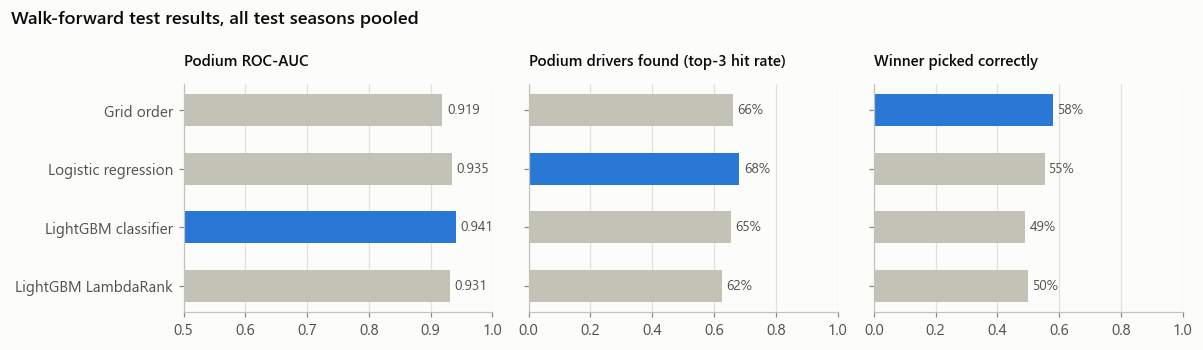

In [3]:
fig = plots.model_comparison(metrics)
plots.save(fig, "model_comparison")
plt.show()

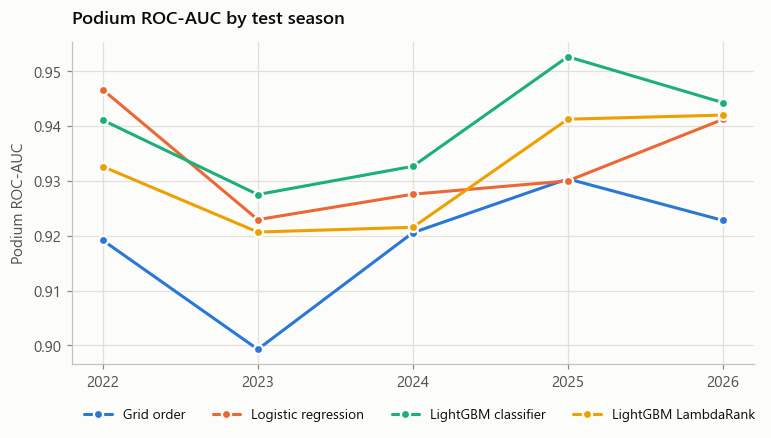

In [4]:
fig = plots.metric_by_season(metrics, "roc_auc", "Podium ROC-AUC")
plots.save(fig, "auc_by_season")
plt.show()

In [5]:
metrics.pivot(index="season", columns="model", values="top3_hit").style.format("{:.1%}")

model,Grid order,LightGBM LambdaRank,LightGBM classifier,Logistic regression
season,,,,
2022,63.6%,62.1%,66.7%,71.2%
2023,63.6%,57.6%,63.6%,62.1%
2024,66.7%,59.7%,62.5%,66.7%
2025,75.0%,70.8%,75.0%,76.4%
2026,60.0%,61.7%,58.3%,63.3%
All,66.1%,62.5%,65.5%,68.2%


### Reading the results

* The learned models produce **better podium probabilities** than the grid alone: the
  LightGBM classifier has a higher ROC-AUC than grid order in every test season (0.941 vs 0.919
  pooled) and the lowest log loss / Brier score. Form and team-strength features add real
  information on top of where a car starts.
* For the harder task of naming **exactly** the three podium finishers or the winner, the grid
  order is a tough baseline. Logistic regression edges it on top-3 hit rate (68 % vs 66 %), but
  nothing beats "the pole-sitter wins" (58 % in the test seasons). DNFs, safety cars and
  first-lap incidents add noise that no pre-race model can see.
* Logistic regression and LambdaRank order the **whole field** best (highest Spearman), which
  is what you would use for midfield or points predictions.

## Calibration

When the model says 30 %, does that driver reach the podium about 30 % of the time?

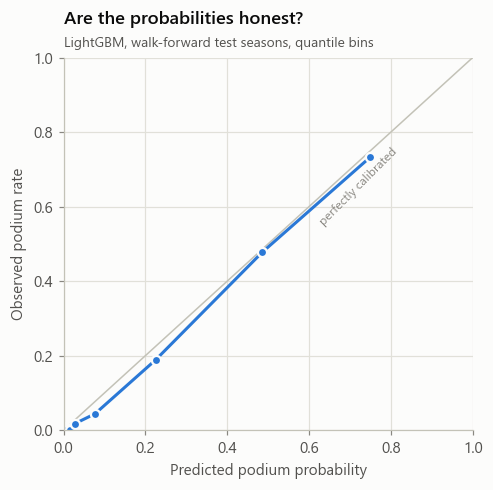

In [6]:
fig = plots.calibration(pred, "p_lgbm")
plots.save(fig, "calibration")
plt.show()

## Which features matter?

Permutation importance on held-out seasons: train the classifier on 2014–2024, shuffle one
feature at a time on 2025–2026, and measure the drop in ROC-AUC.

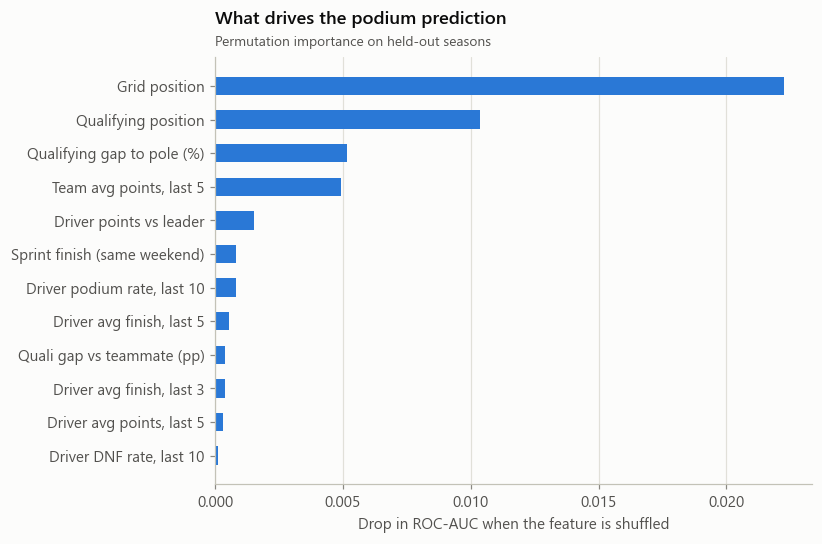

In [7]:
train, hold = df[df["season"] <= 2024], df[df["season"] >= 2025]
clf = m.make_classifier().fit(train[FEATURES], train["podium"])
imp = m.permutation_importance_table(clf, hold[FEATURES], hold["podium"], n_repeats=10)
imp["label"] = imp["feature"].map(FEATURE_LABELS)
imp.to_csv(DATA_PROCESSED / "importance.csv", index=False)
fig = plots.importance(imp)
plots.save(fig, "feature_importance")
plt.show()

## Regulation drift: does a 2014–2025 model still work in 2026?

2026 brought new chassis and power-unit rules, a new team (Cadillac), Audi taking over Sauber
and a reshuffled pecking order. The model uses *rolling* form rather than team identity, so
we expect it to struggle at first, while form carried over from the old rules is
misleading, and to recover once a few 2026 races are in the window. The table below compares
ROC-AUC in rounds 1–5 against rounds 6 and later.

In [8]:
p26 = pred[pred["season"] == 2026]
early = m.evaluate(p26[p26["round"] <= 5], by=None).assign(rounds="1-5")
late = m.evaluate(p26[p26["round"] > 5], by=None).assign(rounds="6+")
drift = pd.concat([early, late])
drift.pivot(index="model", columns="rounds", values="roc_auc").style.format("{:.3f}")

rounds,1-5,6+
model,,
Grid order,0.944,0.916
LightGBM LambdaRank,0.938,0.943
LightGBM classifier,0.942,0.945
Logistic regression,0.924,0.947


In the first five rounds of 2026 the learned models were **no better than the grid**: the
rolling form they rely on still described the 2025 cars. From round 6 onward they pulled clearly
ahead (LightGBM 0.945 vs grid 0.916). A production version would down-weight pre-reset form
after a regulation change.

## Final model#
Retrain the podium classifier on every race so far and save it for the app / notebook 04.

In [9]:
bundle = m.train_final(df)
path = m.save_bundle(bundle)
print(f"Saved {path.name}: trained through {bundle['trained_through']} on {bundle['n_rows']:,} rows")

Saved podium_lgbm.joblib: trained through 2026-11-08 on 5,545 rows
